# 03 - Imbalance Experiments

Fraud is <0.2% of the data, so we compare four approaches:

| Model | How it handles the rare class |
|---|---|
| Logistic Regression (baseline) | Does nothing - our starting point |
| Logistic Regression (class-weighted) | Mistakes on fraud cost more during training |
| Logistic Regression (SMOTE) | Creates synthetic fraud examples - **training data only** |
| Random Forest (class-weighted) | A stronger non-linear model, also weighted |

Features: `V1`-`V28`, `log_amount` (log of the amount - reduces the effect of very large values) and `hour`.

In [1]:
import sys
sys.path.append("..")  # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plots import set_style, save, LEGIT_COLOR, FRAUD_COLOR, MUTED_COLOR
set_style()
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
from src.preprocessing import load_clean
from src.features import add_features
from src.train import split_data, train_models
from src.evaluate import model_metrics

df = add_features(load_clean())
X_train, X_test, y_train, y_test = split_data(df)
print(f"Train: {len(X_train):,} rows, {y_train.sum()} frauds")
print(f"Test:  {len(X_test):,} rows, {y_test.sum()} frauds")

Train: 198,608 rows, 331 frauds
Test:  85,118 rows, 142 frauds


## The accuracy trap

A "model" that predicts **legitimate for everything**:

In [3]:
from sklearn.metrics import accuracy_score, recall_score
always_legit = np.zeros(len(y_test))
print(f"Accuracy: {accuracy_score(y_test, always_legit):.4%}")
print(f"Fraud caught (recall): {recall_score(y_test, always_legit):.0%}")

Accuracy: 99.8332%
Fraud caught (recall): 0%


Over 99.8% accurate, and useless. So we judge models on **precision, recall, F1 and PR-AUC**:

- **Recall** - of all real frauds, how many did we catch?
- **Precision** - of all alerts we raised, how many were real fraud?
- **PR-AUC** - precision/recall quality across *every* threshold (1.0 = perfect).

In [4]:
models = train_models(X_train, y_train)

Training Logistic Regression (baseline) ...


Training Logistic Regression (class-weighted) ...


Training Logistic Regression (SMOTE) ...


Training Random Forest (class-weighted) ...


In [5]:
scores = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
results = pd.DataFrame([model_metrics(name, y_test, s) for name, s in scores.items()]).set_index("model")
results[["precision", "recall", "f1", "pr_auc", "true_positives", "false_positives", "false_negatives"]]

,precision,recall,f1,pr_auc,true_positives,false_positives,false_negatives
model,,,,,,,
Logistic Regression (baseline),0.8587,0.5563,0.6752,0.7061,79,13,63
Logistic Regression (class-weighted),0.0509,0.8873,0.0963,0.6911,126,2349,16
Logistic Regression (SMOTE),0.0480,0.8873,0.0911,0.6969,126,2498,16
Random Forest (class-weighted),0.9083,0.7676,0.8321,0.8114,109,11,33


**Reading it (at the default 0.5 threshold):**
- The baseline has decent precision but misses many frauds.
- Class weighting and SMOTE catch more fraud (higher recall) but flood investigators with false alerts (precision collapses). That is the high-recall trap.
- The Random Forest gives the best balance and the highest PR-AUC.

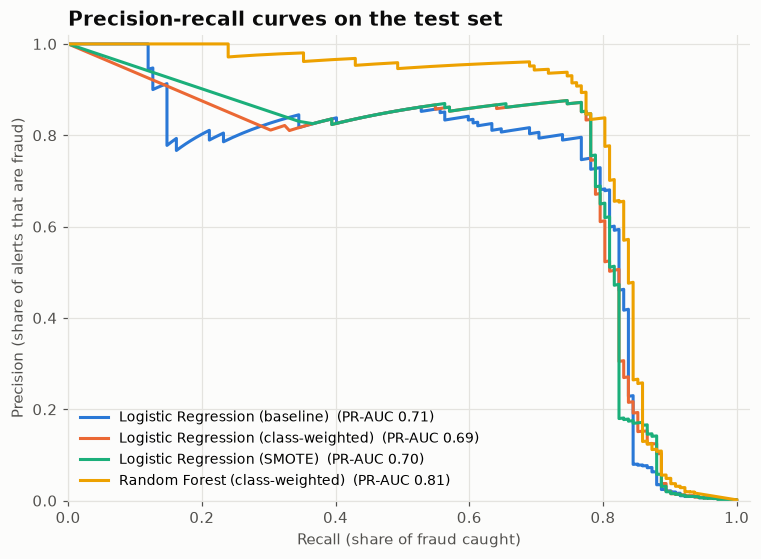

In [6]:
from sklearn.metrics import precision_recall_curve
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

fig, ax = plt.subplots(figsize=(8, 5.5))
for (name, s), color in zip(scores.items(), colors):
    p, r, _ = precision_recall_curve(y_test, s)
    ax.plot(r, p, color=color, label=f"{name}  (PR-AUC {results.loc[name, 'pr_auc']:.2f})")
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Precision-recall curves on the test set")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.legend(loc="lower left", fontsize=9)
save(fig, "05_precision_recall_curves")
plt.show()

## Save test-set scores for notebook 04

In [7]:
test_scores = df.loc[X_test.index, ["transaction_id", "Amount", "Class"]].copy()
for name, s in scores.items():
    test_scores[name] = s
test_scores.to_csv("../data/test_scores.csv", index=False)
results.to_csv("../dashboard/data/model_comparison.csv")
print("Saved data/test_scores.csv and dashboard/data/model_comparison.csv")

Saved data/test_scores.csv and dashboard/data/model_comparison.csv
